<a href="https://colab.research.google.com/github/Ayushmaantiwari/Network_Band/blob/main/Network_Band.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# Cell 1 — Install/import dependencies
!pip -q install nltk scikit-learn pandas scipy matplotlib seaborn

import os, math, time, random, itertools, zipfile, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import milp, LinearConstraint, Bounds, minimize
from scipy.special import expit
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [5]:
# Cell 2 — Parameters
U, N = 8, 16
RB_BW = 180e3
CELL_RADIUS, MIN_DISTANCE = 500.0, 35.0
P_MAX_DBM_VALUES = np.arange(15, 41, 5)
NOISE_PSD_DBM_HZ, NF_DB = -174.0, 9.0
R_MIN = 1e6
SNR_DB = np.arange(0, 19, 3)
# Moderate defaults; increase for publication-quality Monte Carlo estimates.
N_FRAMES = 120
N_CHANNELS = 180
AE_EPOCHS = 35
DNN_EPOCHS = 180
print("Configuration loaded.")

Configuration loaded.


In [6]:
# Cell 3 — Obtain >=20,000 training and >=2,000 test sentences
def load_sentence_corpus():
    try:
        import nltk
        nltk.download('brown', quiet=True)
        nltk.download('punkt', quiet=True)
        nltk.download('punkt_tab', quiet=True)
        from nltk.corpus import brown
        from nltk.tokenize import sent_tokenize
        raw = " ".join(brown.words())
        sents = [s.strip() for s in sent_tokenize(raw) if 20 <= len(s.strip()) <= 240]
        # Brown is finite; repeat deterministically with distinct source sentences
        if len(sents) >= 22000:
            return sents[:20000], sents[20000:22000], "NLTK Brown corpus"
    except Exception as e:
        print("Corpus download/tokenization unavailable:", repr(e))
    # Reproducible fallback: template-generated English-like sentences
    subjects = ["the base station", "the mobile user", "the receiver", "the neural network",
                "the communication channel", "the transmitter", "the resource allocator"]
    verbs = ["estimates", "transmits", "decodes", "optimizes", "measures", "allocates", "reconstructs"]
    objects = ["the received signal", "the channel state", "the information bits",
               "the available bandwidth", "the transmitted sentence", "the power allocation"]
    endings = ["under fading conditions.", "with low error probability.", "using a learned model.",
               "while satisfying the quality constraint.", "over the wireless link."]
    rng = random.Random(SEED)
    data = []
    for _ in range(24000):
        data.append(f"{rng.choice(subjects).capitalize()} {rng.choice(verbs)} "
                    f"{rng.choice(objects)} {rng.choice(endings)}")
    return data[:20000], data[20000:22000], "synthetic fallback"

train_sentences, test_sentences, corpus_name = load_sentence_corpus()
print(corpus_name, "| train:", len(train_sentences), "| test:", len(test_sentences))
print("Example:", train_sentences[0])

NLTK Brown corpus | train: 20000 | test: 2000
Example: The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .


In [7]:
# Cell 4 — Character-level Huffman coding
import heapq
class _Node:
    def __init__(self, freq, ch=None, left=None, right=None):
        self.freq, self.ch, self.left, self.right = freq, ch, left, right
    def __lt__(self, other): return self.freq < other.freq

def build_huffman(text):
    heap = [_Node(v, ch=k) for k,v in Counter(text).items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        root = _Node(heap[0].freq, left=heap[0])
    else:
        while len(heap) > 1:
            a,b = heapq.heappop(heap), heapq.heappop(heap)
            heapq.heappush(heap, _Node(a.freq+b.freq, left=a, right=b))
        root = heap[0]
    codes = {}
    def walk(node, prefix):
        if node.ch is not None: codes[node.ch] = prefix or "0"
        else:
            walk(node.left, prefix+"0"); walk(node.right, prefix+"1")
    walk(root, "")
    return root, codes

HUFF_ROOT, HUFF_CODES = build_huffman("".join(train_sentences))
def huffman_encode(s):
    return np.fromiter((int(b) for ch in s for b in HUFF_CODES[ch]), dtype=np.uint8)
def huffman_decode(bits, root=HUFF_ROOT):
    out=[]; node=root
    for bit in bits:
        node = node.right if int(bit) else node.left
        if node.ch is not None:
            out.append(node.ch); node=root
    return "".join(out)

_probe = "wireless communication"
assert huffman_decode(huffman_encode(_probe)) == _probe
print("Huffman symbols:", len(HUFF_CODES), "| encoded bits:", len(huffman_encode(_probe)))

Huffman symbols: 80 | encoded bits: 96


In [8]:
# Cell 5 — Convolutional encoder, correct puncturing and soft Viterbi decoder
K = 7
G1, G2 = int("133", 8), int("171", 8)

# Mother code rate 1/2. Puncturing masks are applied to the serial
# [v1(0),v2(0),v1(1),v2(1),...] output stream.
# 2/3: retain 3 of 4 coded bits; 3/4: retain 6 of 8 coded bits.
PUNCTURE = {
    "1/2": np.array([1, 1], dtype=np.uint8),
    "2/3": np.array([1, 1, 1, 0], dtype=np.uint8),
    "3/4": np.array([1, 1, 1, 0, 0, 1, 1, 0], dtype=np.uint8),
}

def conv_encode(bits, terminate=True):
    bits = np.asarray(bits, dtype=np.uint8).reshape(-1)
    if terminate:
        bits = np.concatenate([bits, np.zeros(K - 1, dtype=np.uint8)])
    state = 0
    out = np.empty(2 * len(bits), dtype=np.uint8)
    for i, bit in enumerate(bits):
        reg = (state << 1) | int(bit)
        out[2*i] = (reg & G1).bit_count() & 1
        out[2*i+1] = (reg & G2).bit_count() & 1
        state = reg & ((1 << (K - 1)) - 1)
    return out, len(bits)

def puncture_bits(coded, rate):
    mask = np.tile(PUNCTURE[rate],
                   int(np.ceil(len(coded) / len(PUNCTURE[rate]))))[:len(coded)]
    return np.asarray(coded)[mask.astype(bool)]

def depuncture_llr(llr, full_length, rate):
    mask = np.tile(PUNCTURE[rate],
                   int(np.ceil(full_length / len(PUNCTURE[rate]))))[:full_length].astype(bool)
    expected = int(mask.sum())
    if len(llr) != expected:
        raise ValueError(f"LLR length {len(llr)} does not match punctured length {expected}")
    out = np.zeros(full_length, dtype=float)  # zero LLR = erased / unknown bit
    out[mask] = np.asarray(llr, dtype=float)
    return out

def viterbi_decode_soft(llr, n_input_steps):
    """Soft-decision Viterbi decoder; positive LLR favours coded bit 0."""
    llr = np.asarray(llr, dtype=float).reshape(-1)
    if len(llr) != 2 * n_input_steps:
        raise ValueError("Viterbi input must contain two LLRs per trellis step.")

    n_states = 1 << (K - 1)
    inf = 1e100
    metric = np.full(n_states, inf)
    metric[0] = 0.0
    prev_state = np.zeros((n_input_steps, n_states), dtype=np.int16)
    prev_bit = np.zeros((n_input_steps, n_states), dtype=np.uint8)

    # Precompute the two outgoing branches from every state.
    next_state = np.zeros((n_states, 2), dtype=np.int16)
    out_bits = np.zeros((n_states, 2, 2), dtype=np.uint8)
    for st in range(n_states):
        for bit in (0, 1):
            reg = (st << 1) | bit
            next_state[st, bit] = reg & (n_states - 1)
            out_bits[st, bit, 0] = (reg & G1).bit_count() & 1
            out_bits[st, bit, 1] = (reg & G2).bit_count() & 1

    for t in range(n_input_steps):
        l0, l1 = llr[2*t], llr[2*t+1]
        new_metric = np.full(n_states, inf)
        for st in range(n_states):
            if metric[st] >= inf / 2:
                continue
            for bit in (0, 1):
                ns = next_state[st, bit]
                b0, b1 = out_bits[st, bit]
                # Negative log-likelihood, stable for large LLR values.
                branch = np.logaddexp(0.0, -(1 - 2*int(b0))*l0)
                branch += np.logaddexp(0.0, -(1 - 2*int(b1))*l1)
                candidate = metric[st] + branch
                if candidate < new_metric[ns]:
                    new_metric[ns] = candidate
                    prev_state[t, ns] = st
                    prev_bit[t, ns] = bit
        metric = new_metric

    # Encoder is terminated to state zero.
    state = 0
    decoded = np.zeros(n_input_steps, dtype=np.uint8)
    for t in range(n_input_steps - 1, -1, -1):
        decoded[t] = prev_bit[t, state]
        state = prev_state[t, state]
    return decoded[:max(0, n_input_steps - (K - 1))]

# Deterministic noiseless checks for all supported puncturing rates.
_rng = np.random.default_rng(SEED)
_probe_bits = _rng.integers(0, 2, 128, dtype=np.uint8)
for _rate in ("1/2", "2/3", "3/4"):
    _coded, _steps = conv_encode(_probe_bits, terminate=True)
    _tx = puncture_bits(_coded, _rate)
    _llr = (1 - 2*_tx.astype(float)) * 20.0
    _full = depuncture_llr(_llr, len(_coded), _rate)
    _decoded = viterbi_decode_soft(_full, _steps)
    assert np.array_equal(_probe_bits, _decoded), f"Noiseless test failed for {_rate}"
print("Convolutional encoder/Viterbi tests passed for rates 1/2, 2/3 and 3/4.")

Convolutional encoder/Viterbi tests passed for rates 1/2, 2/3 and 3/4.


In [9]:
# Cell 6 — Gray QAM mapping/demapping and channel
def gray_to_binary(g):
    b=g
    shift=g>>1
    while shift:
        b ^= shift; shift >>= 1
    return b

def qam_constellation(M):
    k=int(np.log2(M)); m=int(np.sqrt(M))
    assert m*m==M and M in (4,16,64)
    labels=np.arange(M)
    # Gray-coded PAM index on each axis
    gi=labels >> (k//2); gq=labels & ((1<<(k//2))-1)
    ii=np.array([gray_to_binary(int(x)) for x in gi])
    qq=np.array([gray_to_binary(int(x)) for x in gq])
    levels=np.arange(-(m-1),m,2)
    pts=levels[ii] + 1j*levels[qq]
    pts=pts/np.sqrt(np.mean(np.abs(pts)**2))
    return pts

def qam_mod(bits, M):
    k=int(np.log2(M)); b=np.asarray(bits,dtype=np.uint8)
    pad=(-len(b))%k
    if pad: b=np.r_[b,np.zeros(pad,dtype=np.uint8)]
    labels=b.reshape(-1,k).dot(1 << np.arange(k-1,-1,-1))
    return qam_constellation(M)[labels], pad

def qam_llr(y, M, noise_var):
    k=int(np.log2(M)); const=qam_constellation(M)
    labels=np.arange(M)
    bitmat=((labels[:,None] >> np.arange(k-1,-1,-1)) & 1)
    d=np.abs(y[:,None]-const[None,:])**2
    out=[]
    for j in range(k):
        d0=np.min(d[:,bitmat[:,j]==0],axis=1)
        d1=np.min(d[:,bitmat[:,j]==1],axis=1)
        out.append((d1-d0)/max(noise_var,1e-12))
    return np.stack(out,axis=1).reshape(-1)

def transmit_symbols(symbols, snr_db, fading=False):
    # Unit average symbol energy; complex noise variance = 1/SNR
    snr=10**(snr_db/10); nv=1/snr
    if fading:
        h=(np.random.randn(len(symbols))+1j*np.random.randn(len(symbols)))/np.sqrt(2)
    else: h=np.ones(len(symbols),dtype=complex)
    noise=np.sqrt(nv/2)*(np.random.randn(len(symbols))+1j*np.random.randn(len(symbols)))
    y=h*symbols+noise
    z=y/(h+1e-12) # ZF
    eff_nv=nv/(np.abs(h)**2+1e-12)
    return z, eff_nv

def qam_llr_variable_noise(y,M,nv):
    # Per-symbol max-log demapping; supports per-symbol post-ZF noise variance
    k=int(np.log2(M)); const=qam_constellation(M); labels=np.arange(M)
    bm=((labels[:,None]>>np.arange(k-1,-1,-1))&1)
    d=np.abs(y[:,None]-const[None,:])**2
    L=np.empty((len(y),k))
    for j in range(k):
        L[:,j]=(np.min(d[:,bm[:,j]==1],axis=1)-np.min(d[:,bm[:,j]==0],axis=1))/np.maximum(nv[:,None],1e-12).reshape(-1)
    return L.reshape(-1)

print("QAM constellation sizes:", [len(qam_constellation(m)) for m in (4,16,64)])

QAM constellation sizes: [4, 16, 64]


In [10]:

# Cell 7 — End-to-end frame and Task 1 Monte Carlo (corrected)

MCS = [
    ("QPSK 1/2", 4, "1/2"),
    ("QPSK 3/4", 4, "3/4"),
    ("16-QAM 1/2", 16, "1/2"),
    ("16-QAM 3/4", 16, "3/4"),
    ("64-QAM 2/3", 64, "2/3"),
    ("64-QAM 3/4", 64, "3/4")
]

def txrx_sentence(sentence, snr_db, M, rate, fading=False):
    source_bits = huffman_encode(sentence)

    coded, nsteps = conv_encode(source_bits, terminate=True)
    tx_bits = puncture_bits(coded, rate)

    symbols, pad = qam_mod(tx_bits, M)

    received, noise_var = transmit_symbols(
        symbols, snr_db, fading
    )

    llr = qam_llr_variable_noise(
        received, M, noise_var
    )

    if pad:
        llr = llr[:-pad]

    full_llr = depuncture_llr(
        llr, len(coded), rate
    )

    decoded_bits = viterbi_decode_soft(
        full_llr, nsteps
    )

    recovered_text = huffman_decode(decoded_bits)

    return recovered_text, source_bits, decoded_bits


def run_task1(n_frames=None, snrs=None, fading=False):

    if n_frames is None:
        n_frames = N_FRAMES

    if snrs is None:
        snrs = SNR_DB

    samples = test_sentences[
        :min(n_frames, len(test_sentences))
    ]

    if len(samples) == 0:
        raise ValueError("No test sentences available.")

    rows = []

    for name, M, rate in MCS:

        print(f"\nRunning {name}")

        for snr in snrs:

            bit_errors = 0
            total_bits = 0
            frame_errors = 0

            for sentence in samples:

                original_bits = huffman_encode(sentence)
                total_bits += len(original_bits)

                try:
                    recovered, tx_bits, rx_bits = txrx_sentence(
                        sentence,
                        float(snr),
                        M,
                        rate,
                        fading
                    )

                    frame_errors += int(recovered != sentence)

                    common = min(len(tx_bits), len(rx_bits))

                    errors = np.sum(
                        tx_bits[:common] != rx_bits[:common]
                    )

                    errors += abs(len(tx_bits) - len(rx_bits))

                    bit_errors += int(errors)

                except Exception as exc:

                    frame_errors += 1
                    bit_errors += len(original_bits)

                    print(
                        f"Frame error: {name}, "
                        f"SNR={snr}: {exc}"
                    )

            rows.append({
                "MCS": name,
                "SNR_dB": float(snr),
                "BLER": frame_errors / len(samples),
                "Source_BER": bit_errors / max(total_bits, 1),
                "Frame_errors": frame_errors,
                "Frames_tested": len(samples)
            })

        print(f"Completed {name}")

    results = pd.DataFrame(rows)

    return results


# Use the configured number of frames (120 by default).
# For final statistical evaluation, increase N_FRAMES to 500 or more.

task1_results = run_task1(
    n_frames=N_FRAMES,
    snrs=SNR_DB,
    fading=False
)

display(task1_results)

task1_results.to_csv(
    "/content/task1_mcs_results.csv",
    index=False
)

print("Task 1 simulation completed.")



Running QPSK 1/2
Completed QPSK 1/2

Running QPSK 3/4
Completed QPSK 3/4

Running 16-QAM 1/2
Completed 16-QAM 1/2

Running 16-QAM 3/4
Completed 16-QAM 3/4

Running 64-QAM 2/3
Completed 64-QAM 2/3

Running 64-QAM 3/4
Completed 64-QAM 3/4


,MCS,SNR_dB,BLER,Source_BER,Frame_errors,Frames_tested
0,QPSK 1/2,0.0,0.991667,0.138078,119,120
1,QPSK 1/2,3.0,0.025000,0.000259,3,120
2,QPSK 1/2,6.0,0.000000,0.000000,0,120
3,QPSK 1/2,9.0,0.000000,0.000000,0,120
4,QPSK 1/2,12.0,0.000000,0.000000,0,120
5,QPSK 1/2,15.0,0.000000,0.000000,0,120
6,QPSK 1/2,18.0,0.000000,0.000000,0,120
7,QPSK 3/4,0.0,1.000000,0.468626,120,120
8,QPSK 3/4,3.0,0.983333,0.366945,118,120
9,QPSK 3/4,6.0,0.150000,0.029229,18,120


Task 1 simulation completed.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Evaluating text quality at 0 dB
Evaluating text quality at 6 dB
Evaluating text quality at 12 dB
Evaluating text quality at 18 dB


,SNR_dB,BLEU,Word_accuracy,Sentence_embedding_similarity
0,0,0.299015,0.154321,0.504615
1,6,1.000000,1.000000,1.000000
2,12,1.000000,1.000000,1.000000
3,18,1.000000,1.000000,1.000000


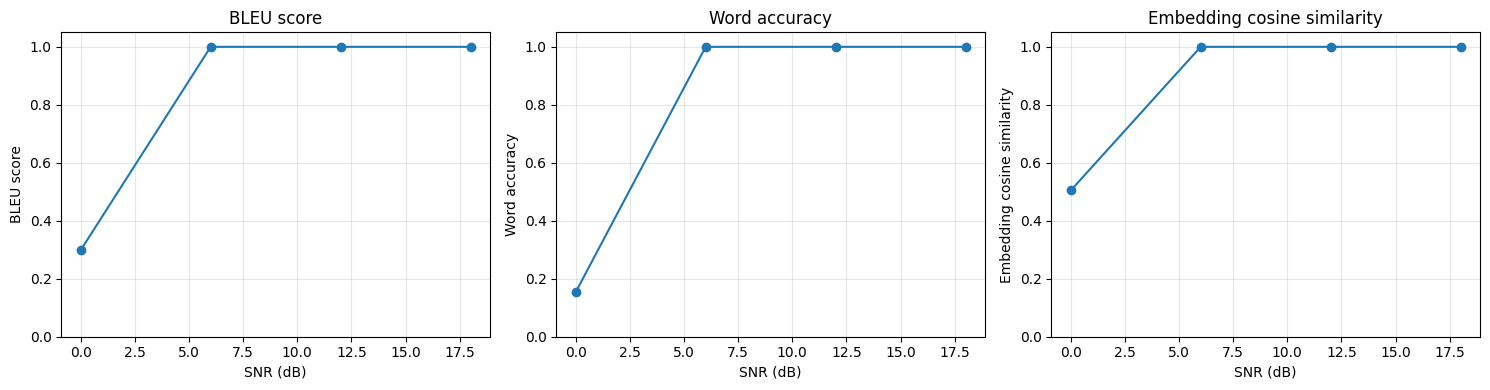

Text quality evaluation completed.


In [11]:

# Cell 8 — Text quality using sentence embeddings and SNR-wise evaluation

import subprocess
import sys

try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "sentence-transformers"
    ])
    from sentence_transformers import SentenceTransformer

from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

# Pretrained semantic sentence embedding model.
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=DEVICE
)

def text_quality(reference, hypothesis):

    ref_words = reference.split()
    hyp_words = hypothesis.split()

    bleu = sentence_bleu(
        [ref_words],
        hyp_words,
        smoothing_function=SmoothingFunction().method1
    )

    matches = sum(
        a == b for a, b in zip(ref_words, hyp_words)
    )

    word_accuracy = matches / max(
        len(ref_words), len(hyp_words), 1
    )

    embeddings = embedding_model.encode(
        [reference, hypothesis],
        normalize_embeddings=True,
        show_progress_bar=False
    )

    similarity = float(
        np.dot(embeddings[0], embeddings[1])
    )

    return bleu, word_accuracy, similarity


# Evaluate multiple SNR values rather than only 12 dB.
QUALITY_SNRS = [0, 6, 12, 18]
QUALITY_FRAMES = min(30, len(test_sentences))

quality_rows = []

for snr in QUALITY_SNRS:

    print(f"Evaluating text quality at {snr} dB")

    for sentence in test_sentences[:QUALITY_FRAMES]:

        try:
            hypothesis, _, _ = txrx_sentence(
                sentence,
                snr,
                4,
                "1/2"
            )

        except Exception:
            hypothesis = ""

        bleu, accuracy, similarity = text_quality(
            sentence,
            hypothesis
        )

        quality_rows.append({
            "SNR_dB": snr,
            "BLEU": bleu,
            "Word_accuracy": accuracy,
            "Sentence_embedding_similarity": similarity
        })


quality_df = pd.DataFrame(quality_rows)

quality_summary = (
    quality_df.groupby("SNR_dB")
    .mean(numeric_only=True)
    .reset_index()
)

display(quality_summary)


# Plot text quality against SNR.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("BLEU", "BLEU score"),
    ("Word_accuracy", "Word accuracy"),
    ("Sentence_embedding_similarity", "Embedding cosine similarity")
]

for ax, (column, title) in zip(axes, metrics):

    ax.plot(
        quality_summary["SNR_dB"],
        quality_summary[column],
        marker="o"
    )

    ax.set_title(title)
    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel(title)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Save text quality lookup table.
quality_summary.to_csv(
    "/content/text_quality_lookup.csv",
    index=False
)

print("Text quality evaluation completed.")


Hamming hard and ML noiseless tests passed.
Epoch 25/250, Loss=2.4461
Epoch 50/250, Loss=1.8293
Epoch 75/250, Loss=1.0389
Epoch 100/250, Loss=0.5961
Epoch 125/250, Loss=0.3192
Epoch 150/250, Loss=0.1173
Epoch 175/250, Loss=0.0612
Epoch 200/250, Loss=0.0834
Epoch 225/250, Loss=0.0315
Epoch 250/250, Loss=0.0324


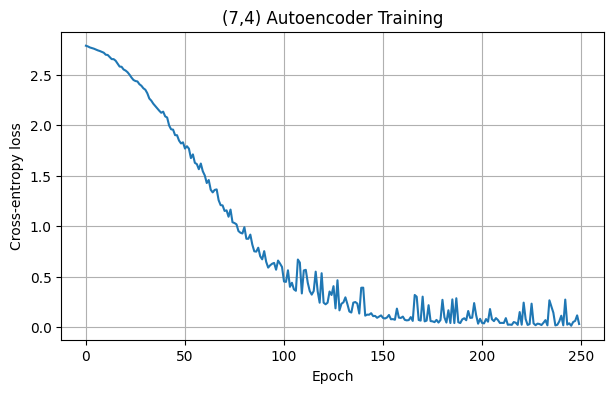

In [12]:

# Cell 9 — Corrected (7,4) Autoencoder and Hamming ML decoder

class AE74(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(16, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 7)
        )

        self.decoder = nn.Sequential(
            nn.Linear(7, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 16)
        )

    def normalize_codeword(self, z):

        power = torch.mean(z ** 2, dim=1, keepdim=True)

        return z / torch.sqrt(power + 1e-8)

    def forward(self, x, noise_std=0.0):

        z = self.normalize_codeword(self.encoder(x))

        y = z + noise_std * torch.randn_like(z)

        return self.decoder(y), z


def train_ae74(epochs=250, batch_size=2048):

    model = AE74().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0005
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=15
    )

    losses = []

    for epoch in range(epochs):

        ids = torch.randint(
            0, 16, (batch_size,), device=DEVICE
        )

        onehot = F.one_hot(ids, 16).float()

        # Random SNR training improves robustness.
        snr_db = np.random.uniform(0, 12)

        noise_std = float(
            np.sqrt(1.0 / (2 * 10**(snr_db / 10)))
        )

        logits, _ = model(onehot, noise_std)

        loss = F.cross_entropy(logits, ids)

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 2.0
        )

        optimizer.step()
        scheduler.step(loss.detach())

        losses.append(loss.item())

        if (epoch + 1) % 25 == 0:
            print(
                f"Epoch {epoch+1}/{epochs}, "
                f"Loss={loss.item():.4f}"
            )

    return model, losses


# Hamming (7,4) encoder.
def hamming74_encode(msg):

    d1, d2, d3, d4 = np.asarray(
        msg, dtype=np.uint8
    )

    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4

    return np.array(
        [p1, p2, d1, p4, d2, d3, d4],
        dtype=np.uint8
    )


# Message index and codeword index use the same bit ordering.
HAM_CODE = np.array([
    hamming74_encode([
        (m >> i) & 1 for i in (3, 2, 1, 0)
    ])
    for m in range(16)
], dtype=np.uint8)

HAM_SYMBOLS = 1.0 - 2.0 * HAM_CODE.astype(float)


def hamming_decode_batch(received, mode="ml"):

    received = np.asarray(received, dtype=float)

    if received.ndim == 1:
        received = received.reshape(1, -1)

    if mode == "hard":

        received_bits = (
            received < 0
        ).astype(np.uint8)

        distances = np.sum(
            received_bits[:, None, :] != HAM_CODE[None, :, :],
            axis=2
        )

    elif mode == "ml":

        # ML decoding: choose the nearest valid BPSK codeword.
        distances = np.sum(
            (
                received[:, None, :]
                - HAM_SYMBOLS[None, :, :]
            ) ** 2,
            axis=2
        )

    else:
        raise ValueError("Mode must be 'hard' or 'ml'.")

    return np.argmin(distances, axis=1)


def evaluate_ae74(
    model,
    snrs_db,
    channel="awgn",
    n=10000
):

    results = []

    model.eval()

    with torch.no_grad():

        for snr_db in snrs_db:

            ids = np.random.randint(0, 16, n)

            onehot = np.eye(16, dtype=np.float32)[ids]

            z = model.encoder(
                torch.tensor(onehot, device=DEVICE)
            )

            z = model.normalize_codeword(z).cpu().numpy()

            noise_var = 1.0 / (10**(snr_db / 10))

            if channel == "rayleigh":

                h = np.random.rayleigh(
                    scale=1/np.sqrt(2),
                    size=(n, 1)
                )

            elif channel == "awgn":

                h = np.ones((n, 1))

            else:
                raise ValueError("Unknown channel.")

            # Autoencoder transmission.
            noise_ae = np.sqrt(noise_var / 2) * np.random.randn(n, 7)

            y_ae = h * z + noise_ae

            # Receiver knows CSI.
            y_ae_eq = y_ae / np.maximum(h, 1e-9)

            logits = model.decoder(
                torch.tensor(
                    y_ae_eq,
                    dtype=torch.float32,
                    device=DEVICE
                )
            )

            ae_pred = logits.argmax(dim=1).cpu().numpy()

            # Generate Hamming messages.
            message_bits = np.array([
                [(m >> i) & 1 for i in (3, 2, 1, 0)]
                for m in ids
            ], dtype=np.uint8)

            codewords = HAM_CODE[ids]

            bpsk = 1.0 - 2.0 * codewords.astype(float)

            noise_h = np.sqrt(noise_var / 2) * np.random.randn(n, 7)

            y_h = h * bpsk + noise_h

            y_h_eq = y_h / np.maximum(h, 1e-9)

            hard_pred = hamming_decode_batch(
                y_h_eq, mode="hard"
            )

            ml_pred = hamming_decode_batch(
                y_h_eq, mode="ml"
            )

            # Uncoded BPSK baseline.
            uncoded_bpsk = (
                1.0 - 2.0 * message_bits.astype(float)
            )

            noise_u = np.sqrt(noise_var / 2) * np.random.randn(n, 4)

            y_u = h * uncoded_bpsk + noise_u

            uncoded_pred = (
                y_u / np.maximum(h, 1e-9) < 0
            ).astype(np.uint8)

            uncoded_bler = np.mean(
                np.any(uncoded_pred != message_bits, axis=1)
            )

            results.append({

                "SNR_dB": snr_db,

                "AE_BLER": np.mean(ae_pred != ids),

                "Hamming_hard_BLER": np.mean(
                    hard_pred != ids
                ),

                "Hamming_ML_BLER": np.mean(
                    ml_pred != ids
                ),

                "Uncoded_BPSK_4bit_BLER": uncoded_bler
            })

    return pd.DataFrame(results)


# Noiseless decoder validation.
all_ids = np.arange(16)

assert np.array_equal(
    hamming_decode_batch(
        HAM_SYMBOLS, mode="ml"
    ),
    all_ids
)

assert np.array_equal(
    hamming_decode_batch(
        HAM_SYMBOLS, mode="hard"
    ),
    all_ids
)

print("Hamming hard and ML noiseless tests passed.")

# Train autoencoder.
ae74, ae_loss = train_ae74()

plt.figure(figsize=(7, 4))
plt.plot(ae_loss)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("(7,4) Autoencoder Training")
plt.grid(True)
plt.show()


AWGN results


,SNR_dB,AE_BLER,Hamming_hard_BLER,Hamming_ML_BLER,Uncoded_BPSK_4bit_BLER
0,0,0.0737,0.1013,0.0478,0.2818
1,2,0.0182,0.0275,0.0083,0.1485
2,4,0.0018,0.0029,0.0006,0.0518
3,6,0.0000,0.0000,0.0000,0.0102
4,8,0.0000,0.0000,0.0000,0.0006
5,10,0.0000,0.0000,0.0000,0.0001
6,12,0.0000,0.0000,0.0000,0.0000


Rayleigh results


,SNR_dB,AE_BLER,Hamming_hard_BLER,Hamming_ML_BLER,Uncoded_BPSK_4bit_BLER
0,0,0.2533,0.2819,0.2359,0.4100
1,2,0.1942,0.2060,0.1669,0.3182
2,4,0.1261,0.1346,0.1077,0.2305
3,6,0.0830,0.0877,0.0723,0.1560
4,8,0.0545,0.0622,0.0483,0.1096
5,10,0.0355,0.0424,0.0324,0.0707
6,12,0.0227,0.0227,0.0176,0.0447


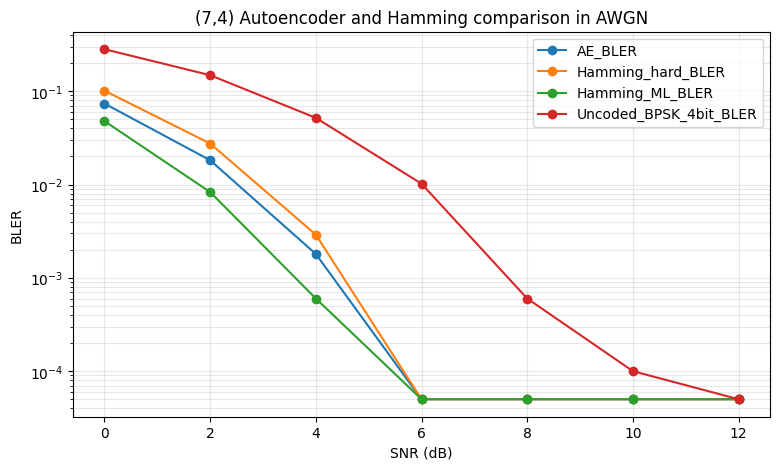

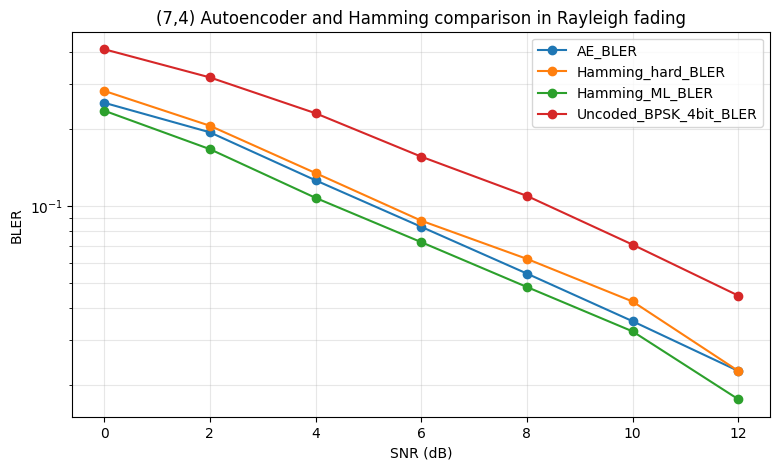

,SNR_dB,Learned_AE_BLER,Conventional_16QAM_BLER
0,0,0.72535,0.73445
1,2,0.65675,0.67710
2,4,0.57705,0.59350
3,6,0.47165,0.48350
4,8,0.34955,0.35135
5,10,0.24090,0.22165
6,12,0.16195,0.11275
7,14,0.09840,0.03600
8,16,0.06210,0.00665
9,18,0.04015,0.00045


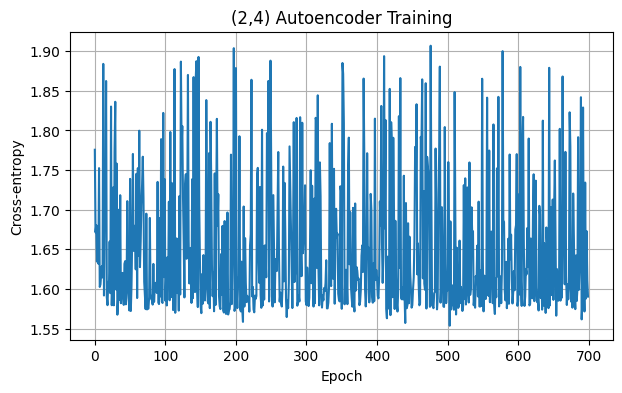

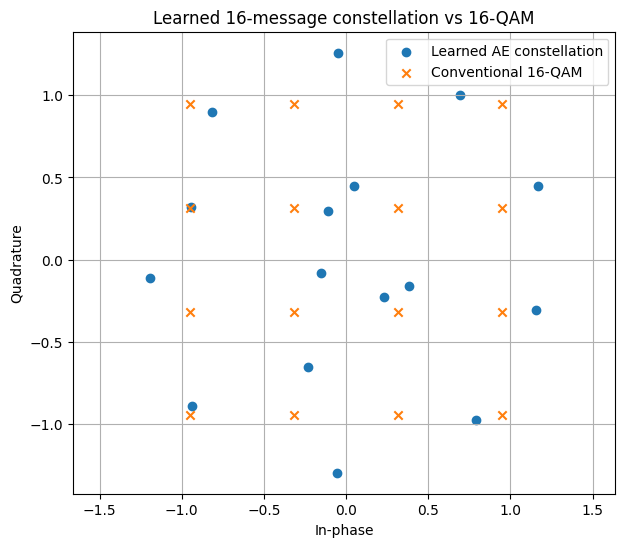

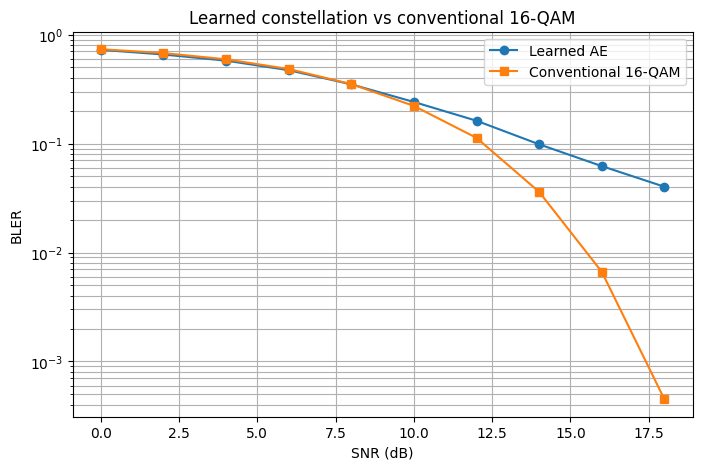

Task 2 evaluation completed.


In [13]:

# Cell 10 — AWGN/Rayleigh evaluation and (2,4) constellation comparison

AE_SNRS = np.arange(0, 13, 2)

# Fresh evaluation: do not reuse old/stale results.
ae_awgn = evaluate_ae74(
    ae74,
    AE_SNRS,
    channel="awgn",
    n=10000
)

ae_rayleigh = evaluate_ae74(
    ae74,
    AE_SNRS,
    channel="rayleigh",
    n=10000
)

print("AWGN results")
display(ae_awgn)

print("Rayleigh results")
display(ae_rayleigh)


# Plot AWGN results.
plt.figure(figsize=(9, 5))

for col in ae_awgn.columns[1:]:

    plt.semilogy(
        ae_awgn["SNR_dB"],
        np.maximum(ae_awgn[col], 0.5/10000),
        marker="o",
        label=col
    )

plt.xlabel("SNR (dB)")
plt.ylabel("BLER")
plt.title("(7,4) Autoencoder and Hamming comparison in AWGN")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


# Plot Rayleigh results.
plt.figure(figsize=(9, 5))

for col in ae_rayleigh.columns[1:]:

    plt.semilogy(
        ae_rayleigh["SNR_dB"],
        np.maximum(ae_rayleigh[col], 0.5/10000),
        marker="o",
        label=col
    )

plt.xlabel("SNR (dB)")
plt.ylabel("BLER")
plt.title("(7,4) Autoencoder and Hamming comparison in Rayleigh fading")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


# -------------------------------------------------------
# Experiment B: (2,4) Autoencoder
# -------------------------------------------------------

class AE16(nn.Module):

    def __init__(self):

        super().__init__()

        self.points = nn.Parameter(
            torch.randn(16, 2) * 0.5
        )

    def normalized_points(self):

        p = self.points

        power = torch.mean(torch.sum(p**2, dim=1))

        return p / torch.sqrt(power + 1e-8)

    def forward(self, ids, noise_std=0.0):

        p = self.normalized_points()

        y = p[ids] + noise_std * torch.randn(
            len(ids), 2, device=ids.device
        )

        logits = -torch.cdist(y, p)**2

        return logits, p


# Train the learned 16-point constellation.
ae16 = AE16().to(DEVICE)

optimizer16 = torch.optim.Adam(
    ae16.parameters(),
    lr=0.01
)

loss16 = []

for epoch in range(700):

    ids = torch.randint(
        0, 16, (2048,), device=DEVICE
    )

    # Randomized SNR training.
    snr_db = np.random.uniform(2, 18)

    noise_std = float(
        np.sqrt(1 / (2 * 10**(snr_db / 10)))
    )

    logits, points = ae16(ids, noise_std)

    loss = F.cross_entropy(logits, ids)

    optimizer16.zero_grad()
    loss.backward()
    optimizer16.step()

    loss16.append(loss.item())


# Evaluate learned constellation and conventional 16-QAM.
def evaluate_ae16(model, snrs_db, n=20000):

    results = []

    model.eval()

    with torch.no_grad():

        learned = model.normalized_points().cpu().numpy()

        qam = qam_constellation(16)

        qam_points = np.column_stack([
            qam.real,
            qam.imag
        ])

        for snr_db in snrs_db:

            ids = np.random.randint(0, 16, n)

            noise_std = np.sqrt(
                1 / (2 * 10**(snr_db / 10))
            )

            noise = noise_std * np.random.randn(n, 2)

            # Learned constellation.
            y_learned = learned[ids] + noise

            dist_learned = np.sum(
                (
                    y_learned[:, None, :]
                    - learned[None, :, :]
                )**2,
                axis=2
            )

            pred_learned = np.argmin(
                dist_learned, axis=1
            )

            # Conventional 16-QAM.
            y_qam = qam_points[ids] + noise

            dist_qam = np.sum(
                (
                    y_qam[:, None, :]
                    - qam_points[None, :, :]
                )**2,
                axis=2
            )

            pred_qam = np.argmin(
                dist_qam, axis=1
            )

            results.append({

                "SNR_dB": snr_db,

                "Learned_AE_BLER": np.mean(
                    pred_learned != ids
                ),

                "Conventional_16QAM_BLER": np.mean(
                    pred_qam != ids
                )
            })

    return pd.DataFrame(results)


ae16_results = evaluate_ae16(
    ae16,
    np.arange(0, 19, 2)
)

display(ae16_results)


# Plot learned constellation training loss.
plt.figure(figsize=(7, 4))
plt.plot(loss16)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy")
plt.title("(2,4) Autoencoder Training")
plt.grid(True)
plt.show()


# Constellation comparison.
with torch.no_grad():

    learned = ae16.normalized_points().cpu().numpy()

qam16 = qam_constellation(16)

plt.figure(figsize=(7, 6))

plt.scatter(
    learned[:, 0],
    learned[:, 1],
    label="Learned AE constellation"
)

plt.scatter(
    qam16.real,
    qam16.imag,
    marker="x",
    label="Conventional 16-QAM"
)

plt.xlabel("In-phase")
plt.ylabel("Quadrature")
plt.title("Learned 16-message constellation vs 16-QAM")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


# Quantitative comparison.
plt.figure(figsize=(8, 5))

plt.semilogy(
    ae16_results["SNR_dB"],
    np.maximum(ae16_results["Learned_AE_BLER"], 0.5/20000),
    marker="o",
    label="Learned AE"
)

plt.semilogy(
    ae16_results["SNR_dB"],
    np.maximum(ae16_results["Conventional_16QAM_BLER"], 0.5/20000),
    marker="s",
    label="Conventional 16-QAM"
)

plt.xlabel("SNR (dB)")
plt.ylabel("BLER")
plt.title("Learned constellation vs conventional 16-QAM")
plt.grid(True, which="both")
plt.legend()
plt.show()


# Save results.
ae_awgn.to_csv("/content/AE_AWGN_results.csv", index=False)
ae_rayleigh.to_csv("/content/AE_Rayleigh_results.csv", index=False)
ae16_results.to_csv("/content/AE16_results.csv", index=False)

print("Task 2 evaluation completed.")


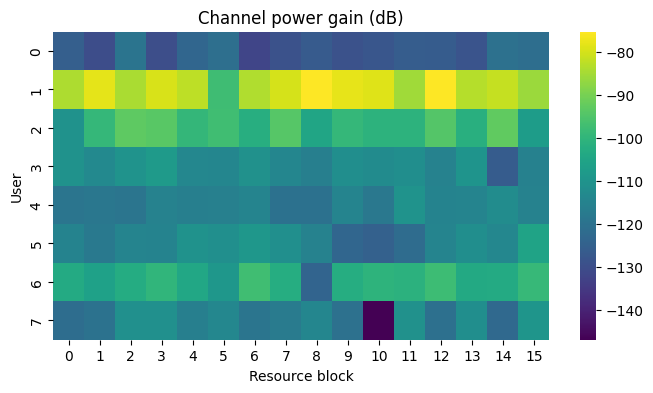

Integrated noise per RB (dBm): -112.44727494896694


In [14]:
# Cell 11 — Channel generation and rate calculations
def dbm_to_watt(dbm): return 10**((dbm-30)/10)
def generate_channel():
    # Uniform users in cell area, with minimum radius
    r=np.sqrt(np.random.uniform(MIN_DISTANCE**2,CELL_RADIUS**2,U))
    pl_db=128.1+37.6*np.log10(r/1000.0)
    shadow=np.random.normal(0,8,U)
    path_gain=10**(-(pl_db+shadow)/10)
    rayleigh=np.random.exponential(1.0,size=(U,N))
    return path_gain[:,None]*rayleigh, r, pl_db+shadow

noise_dbm=NOISE_PSD_DBM_HZ+10*np.log10(RB_BW)+NF_DB
NOISE_W=dbm_to_watt(noise_dbm)
def rate_matrix(g,p_per_rb):
    snr=g*p_per_rb/NOISE_W
    return RB_BW*np.log2(1+snr)

g_demo,dist_demo,loss_demo=generate_channel()
plt.figure(figsize=(8,4)); sns.heatmap(10*np.log10(g_demo+1e-30),annot=False,cmap='viridis')
plt.xlabel('Resource block'); plt.ylabel('User'); plt.title('Channel power gain (dB)'); plt.show()
print("Integrated noise per RB (dBm):",noise_dbm)

In [15]:

# Cell 12 — Corrected MILP and QoS-constrained power allocation

from scipy.optimize import (
    milp, LinearConstraint, Bounds, minimize
)

def round_robin_assignment():

    x = np.zeros((U, N), dtype=int)

    for n in range(N):
        x[n % U, n] = 1

    return x


def strongest_assignment(g):

    x = np.zeros((U, N), dtype=int)

    x[np.argmax(g, axis=0), np.arange(N)] = 1

    return x


def solve_milp_equal_power(g, pmax_w):

    p_rb = pmax_w / N

    rates = rate_matrix(g, p_rb)

    c = -rates.reshape(-1)

    # At most one user per resource block.
    A_rb = np.zeros((N, U*N))

    for n in range(N):
        A_rb[n, n::N] = 1.0

    # Minimum rate constraint for every user.
    A_qos = np.zeros((U, U*N))

    for u in range(U):
        A_qos[u, u*N:(u+1)*N] = -rates[u]

    constraints = [

        LinearConstraint(
            A_rb,
            np.zeros(N),
            np.ones(N)
        ),

        LinearConstraint(
            A_qos,
            -np.inf*np.ones(U),
            -R_MIN*np.ones(U)
        )
    ]

    result = milp(

        c=c,

        integrality=np.ones(U*N),

        bounds=Bounds(
            np.zeros(U*N),
            np.ones(U*N)
        ),

        constraints=constraints,

        # No intentional optimality gap.
        options={
            "time_limit": 30.0,
            "mip_rel_gap": 0.0
        }
    )

    if result.x is None:

        return (
            strongest_assignment(g),
            False,
            result.message
        )

    assignment = (
        result.x.reshape(U, N) > 0.5
    ).astype(int)

    # Check actual feasibility.
    user_rates = np.sum(
        rates * assignment,
        axis=1
    )

    feasible = (
        np.all(user_rates >= R_MIN - 1e-3)
        and np.all(assignment.sum(axis=0) <= 1)
    )

    optimal = (
        result.success
        and feasible
    )

    return assignment, optimal, result.message


def constrained_waterfill(g, x, pmax_w):

    """
    Numerical solution of the fixed-assignment,
    QoS-constrained concave power allocation problem.

    The SLSQP solver enforces the primal power and
    minimum-rate constraints. It is not an unconstrained
    textbook water-filling approximation.
    """

    x = np.asarray(x, dtype=int)

    idx = np.argwhere(x > 0)

    p_rb = np.zeros(N)

    if len(idx) == 0:
        return p_rb, False

    users = idx[:, 0]
    rb_ids = idx[:, 1]

    a = g[users, rb_ids] / NOISE_W

    counts = np.bincount(
        users,
        minlength=U
    )

    if np.any(counts == 0):
        return p_rb, False

    # Minimum initial power for equal rate contribution
    # across the assigned RBs of each user.
    p_min = (
        2**(R_MIN / (RB_BW * counts[users])) - 1
    ) / np.maximum(a, 1e-30)

    if np.sum(p_min) > pmax_w:
        return p_rb, False

    def objective(p):

        return -np.sum(
            RB_BW * np.log2(1 + a*p)
        )

    constraints = [

        {
            "type": "ineq",
            "fun": lambda p: pmax_w - np.sum(p)
        }
    ]

    for u in range(U):

        mask = users == u

        constraints.append({

            "type": "ineq",

            "fun": lambda p, mask=mask:

                np.sum(
                    RB_BW * np.log2(
                        1 + a[mask]*p[mask]
                    )
                ) - R_MIN

        })

    p0 = p_min.copy()

    residual = max(
        0.0,
        pmax_w - np.sum(p0)
    )

    p0 += residual / len(p0)

    result = minimize(

        objective,

        p0,

        method="SLSQP",

        bounds=[
            (0.0, pmax_w)
            for _ in range(len(p0))
        ],

        constraints=constraints,

        options={
            "maxiter": 300,
            "ftol": 1e-10,
            "disp": False
        }
    )

    candidate = np.maximum(
        result.x, 0.0
    )

    user_rates = np.zeros(U)

    for j, (u, n) in enumerate(idx):

        user_rates[u] += (
            RB_BW *
            np.log2(
                1 + g[u, n]*candidate[j]/NOISE_W
            )
        )

    feasible = (

        np.sum(candidate) <= pmax_w + 1e-9

        and np.all(
            user_rates >= R_MIN - 1e-3
        )
    )

    if not feasible:
        return p_rb, False

    p_rb[rb_ids] = candidate

    return p_rb, True


def evaluate_allocation(g, x, p_rb):

    user_rates = np.zeros(U)

    for u in range(U):

        selected = np.where(
            np.asarray(x)[u] > 0
        )[0]

        if len(selected):

            user_rates[u] = np.sum(

                RB_BW * np.log2(

                    1 + g[u, selected] *
                    p_rb[selected] / NOISE_W

                )
            )

    sum_rate = np.sum(user_rates)

    fairness = (
        sum_rate**2 /
        (U*np.sum(user_rates**2) + 1e-12)
    )

    return {

        "Sum_rate_Mbps": sum_rate / 1e6,

        "QoS_users_pct": (
            100*np.mean(user_rates >= R_MIN)
        ),

        "Jain_fairness": fairness,

        "Rate_5th_percentile_Mbps": (
            np.percentile(user_rates, 5) / 1e6
        ),

        "User_rates_Mbps": user_rates / 1e6
    }


def benchmark_methods(g, pmax_w):

    methods = {}

    # 1. Round robin with equal power.
    x_rr = round_robin_assignment()

    methods["Round-robin equal power"] = (
        x_rr,
        np.full(N, pmax_w/N)
    )

    # 2. Strongest user with power refinement.
    x_strong = strongest_assignment(g)

    p_strong, ok_strong = constrained_waterfill(
        g, x_strong, pmax_w
    )

    if not ok_strong:
        p_strong = np.full(N, pmax_w/N)

    methods["Strongest + water-fill"] = (
        x_strong, p_strong
    )

    # 3. MILP with equal power.
    x_milp, milp_ok, milp_message = solve_milp_equal_power(
        g, pmax_w
    )

    methods["MILP equal power"] = (
        x_milp,
        np.full(N, pmax_w/N)
    )

    # 4. MILP assignment followed by power refinement.
    p_milp, ok_milp = constrained_waterfill(
        g, x_milp, pmax_w
    )

    if not ok_milp:
        p_milp = np.full(N, pmax_w/N)

    methods["MILP + water-fill"] = (
        x_milp, p_milp
    )

    return methods


Epoch 30/300 | Loss=31.6990 | Smoothed=28.2264 | LR=0.000300
Epoch 60/300 | Loss=20.3820 | Smoothed=24.7325 | LR=0.000150
Epoch 90/300 | Loss=24.2134 | Smoothed=24.7287 | LR=0.000150
Epoch 120/300 | Loss=27.0999 | Smoothed=25.9258 | LR=0.000075
Epoch 150/300 | Loss=20.7482 | Smoothed=24.5253 | LR=0.000019
Epoch 180/300 | Loss=28.5054 | Smoothed=24.5240 | LR=0.000009
Epoch 210/300 | Loss=17.2943 | Smoothed=22.3475 | LR=0.000005
Epoch 240/300 | Loss=34.3258 | Smoothed=24.0393 | LR=0.000001
Epoch 270/300 | Loss=23.4538 | Smoothed=21.9866 | LR=0.000001
Epoch 300/300 | Loss=33.9358 | Smoothed=24.4940 | LR=0.000000


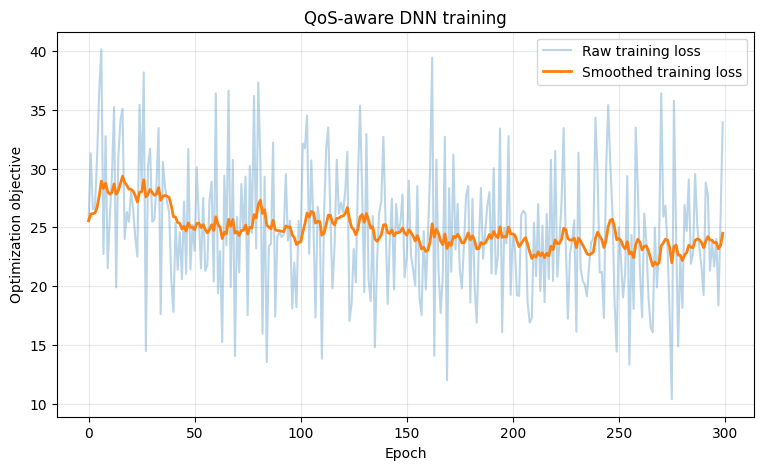

DNN allocation shape: (8, 16)
RBs per user:
[2 2 1 1 4 1 3 2]
Total allocated RBs:
16
Power fractions sum:
0.9999999


In [16]:

# Cell 13 — Improved QoS-aware DNN resource allocation

from scipy.optimize import linear_sum_assignment

class ResourceDNN(nn.Module):

    def __init__(self, U=U, N=N):

        super().__init__()

        self.U = U
        self.N = N

        self.net = nn.Sequential(

            nn.Linear(U*N, 256),
            nn.ReLU(),

            nn.Linear(256, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, U*N + N)
        )

    def forward(self, channel_gain):

        # Normalize input using channel gain relative to noise.
        features = torch.log10(
            channel_gain.clamp_min(1e-30) / NOISE_W
        )

        z = self.net(
            features.reshape(len(channel_gain), -1)
        )

        assignment_logits = z[:, :U*N].reshape(
            -1, U, N
        )

        power_logits = z[:, U*N:]

        return assignment_logits, power_logits


def train_resource_dnn(
    epochs=300,
    batch=128,
    qos_weight=50.0
):

    model = ResourceDNN().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=3e-4,
        weight_decay=1e-5
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=20
    )

    losses = []
    smoothed_losses = []

    for epoch in range(epochs):

        # Generate random channel realizations.
        g_batch = np.stack([
            generate_channel()[0]
            for _ in range(batch)
        ])

        p_batch = dbm_to_watt(
            np.random.uniform(15, 40, batch)
        )

        gt = torch.tensor(
            g_batch,
            dtype=torch.float32,
            device=DEVICE
        )

        pt = torch.tensor(
            p_batch,
            dtype=torch.float32,
            device=DEVICE
        )

        assignment_logits, power_logits = model(gt)

        # Soft RB assignment.
        assignment_soft = F.softmax(
            assignment_logits,
            dim=1
        )

        # Power distribution over RBs.
        power_soft = (
            F.softmax(power_logits, dim=1)
            * pt.unsqueeze(1)
        )

        # Received SNR.
        snr = (
            gt *
            power_soft[:, None, :]
            / NOISE_W
        )

        # Rate contribution for every user/RB pair.
        rates = (
            RB_BW *
            torch.log2(1 + snr) *
            assignment_soft
        )

        user_rates = rates.sum(dim=2)

        sum_rate_mbps = (
            rates.sum(dim=(1, 2)) / 1e6
        )

        user_rates_mbps = user_rates / 1e6

        # QoS deficit.
        qos_deficit = F.relu(
            R_MIN/1e6 - user_rates_mbps
        )

        qos_penalty = qos_deficit.sum(dim=1)

        # Soft optimization objective.
        loss = (
            -sum_rate_mbps
            + qos_weight*qos_penalty
        ).mean()

        optimizer.zero_grad()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=2.0
        )

        optimizer.step()

        loss_value = float(loss.detach().cpu())

        losses.append(loss_value)

        scheduler.step(loss_value)

        if epoch == 0:
            smoothed = loss_value
        else:
            smoothed = (
                0.9*smoothed
                + 0.1*loss_value
            )

        smoothed_losses.append(smoothed)

        if (epoch+1) % 30 == 0:

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Loss={loss_value:.4f} | "
                f"Smoothed={smoothed:.4f} | "
                f"LR={optimizer.param_groups[0]['lr']:.6f}"
            )

    return model, losses, smoothed_losses


def predict_dnn(model, g, pmax_w):

    model.eval()

    with torch.no_grad():

        gt = torch.tensor(
            g[None, :, :],
            dtype=torch.float32,
            device=DEVICE
        )

        logits, power_logits = model(gt)

        scores = logits[0].cpu().numpy()

        power_fraction = (
            F.softmax(power_logits[0], dim=0)
            .cpu().numpy()
        )

    # First allocate one distinct RB to each user.
    user_rows, rb_cols = linear_sum_assignment(
        -scores
    )

    assignment = np.zeros(
        (U, N),
        dtype=int
    )

    assignment[user_rows, rb_cols] = 1

    # Allocate remaining RBs according to DNN scores.
    for n in range(N):

        if assignment[:, n].sum() == 0:

            u = int(np.argmax(scores[:, n]))

            assignment[u, n] = 1

    assert np.all(
        assignment.sum(axis=0) == 1
    )

    assert np.all(
        assignment.sum(axis=1) >= 1
    )

    return assignment, power_fraction


# Train DNN.
resource_dnn, dnn_losses, dnn_smoothed_losses = (
    train_resource_dnn()
)


# Plot training convergence.
plt.figure(figsize=(9, 5))

plt.plot(
    dnn_losses,
    alpha=0.3,
    label="Raw training loss"
)

plt.plot(
    dnn_smoothed_losses,
    linewidth=2,
    label="Smoothed training loss"
)

plt.xlabel("Epoch")
plt.ylabel("Optimization objective")
plt.title("QoS-aware DNN training")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# Test allocation.
g_test, _, _ = generate_channel()

x_test, p_test_fraction = predict_dnn(
    resource_dnn,
    g_test,
    dbm_to_watt(30)
)

print("DNN allocation shape:", x_test.shape)

print("RBs per user:")
print(x_test.sum(axis=1))

print("Total allocated RBs:")
print(x_test.sum())

print("Power fractions sum:")
print(p_test_fraction.sum())


Progress: 5/120 | Elapsed: 0.9 seconds
Progress: 10/120 | Elapsed: 1.0 seconds
Progress: 15/120 | Elapsed: 1.3 seconds
Progress: 20/120 | Elapsed: 1.7 seconds
Progress: 25/120 | Elapsed: 2.0 seconds
Progress: 30/120 | Elapsed: 2.0 seconds
Progress: 35/120 | Elapsed: 2.5 seconds
Progress: 40/120 | Elapsed: 4.6 seconds
Progress: 45/120 | Elapsed: 4.8 seconds
Progress: 50/120 | Elapsed: 6.0 seconds
Progress: 55/120 | Elapsed: 6.3 seconds
Progress: 60/120 | Elapsed: 6.7 seconds
Progress: 65/120 | Elapsed: 6.8 seconds
Progress: 70/120 | Elapsed: 7.0 seconds
Progress: 75/120 | Elapsed: 8.0 seconds
Progress: 80/120 | Elapsed: 8.4 seconds
Progress: 85/120 | Elapsed: 9.0 seconds
Progress: 90/120 | Elapsed: 9.8 seconds
Progress: 95/120 | Elapsed: 9.9 seconds
Progress: 100/120 | Elapsed: 9.9 seconds
Progress: 105/120 | Elapsed: 10.1 seconds
Progress: 110/120 | Elapsed: 10.3 seconds
Progress: 115/120 | Elapsed: 10.5 seconds
Progress: 120/120 | Elapsed: 10.6 seconds

Simulation completed in 10.60 s

,Pmax_dBm,Method,Channel_ID,Sum_rate_Mbps,QoS_users_pct,Jain_fairness,Rate_5th_percentile_Mbps,Total_power_W,Execution_time_ms,Power_constraint_satisfied,QoS_solver_feasible
0,15.0,DNN + water-fill,9.5,4.343,15.000,0.680,0.148,0.032,0.181,1.00,0.00
1,15.0,DNN direct,9.5,4.343,15.000,0.680,0.148,0.032,1.034,1.00,1.00
2,15.0,MILP + water-fill,9.5,16.311,35.000,0.297,0.107,0.032,32.085,1.00,0.05
3,15.0,MILP equal power,9.5,16.330,35.000,0.294,0.103,0.032,5.544,1.00,0.10
4,15.0,Round-robin equal power,9.5,6.659,29.375,0.580,0.156,0.032,0.020,1.00,1.00
5,15.0,Strongest + water-fill,9.5,17.779,26.875,0.231,0.000,0.032,0.107,1.00,0.00
6,20.0,DNN + water-fill,9.5,6.900,40.000,0.763,0.316,0.100,0.086,0.70,0.00
7,20.0,DNN direct,9.5,6.900,40.000,0.763,0.316,0.100,1.055,0.70,1.00
8,20.0,MILP + water-fill,9.5,18.785,59.375,0.410,0.449,0.100,137.457,1.00,0.20
9,20.0,MILP equal power,9.5,18.834,59.375,0.404,0.428,0.100,8.853,1.00,0.40


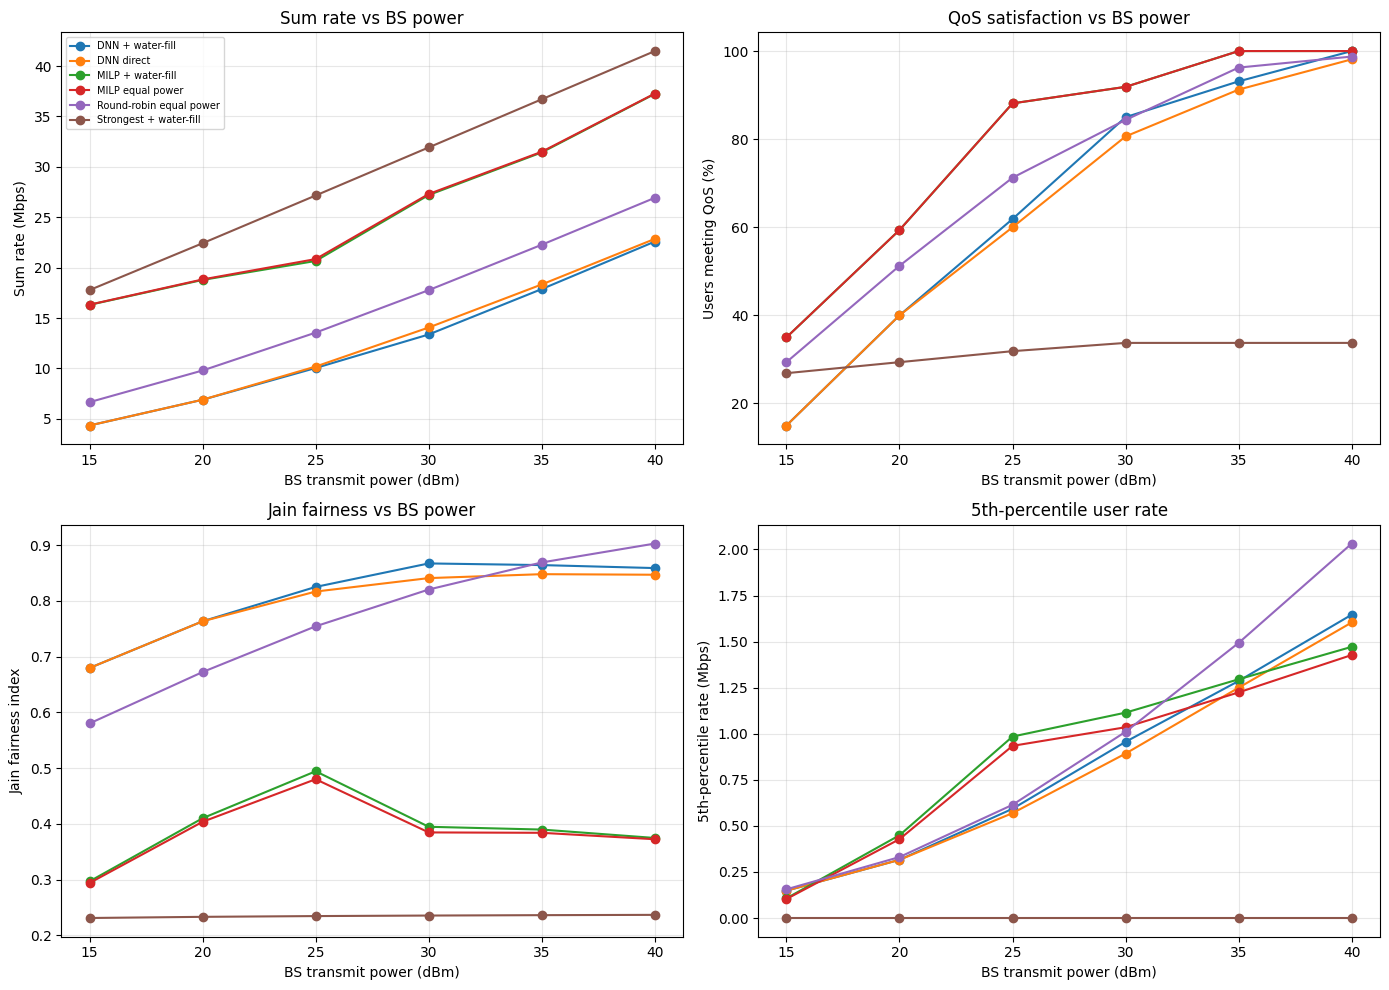

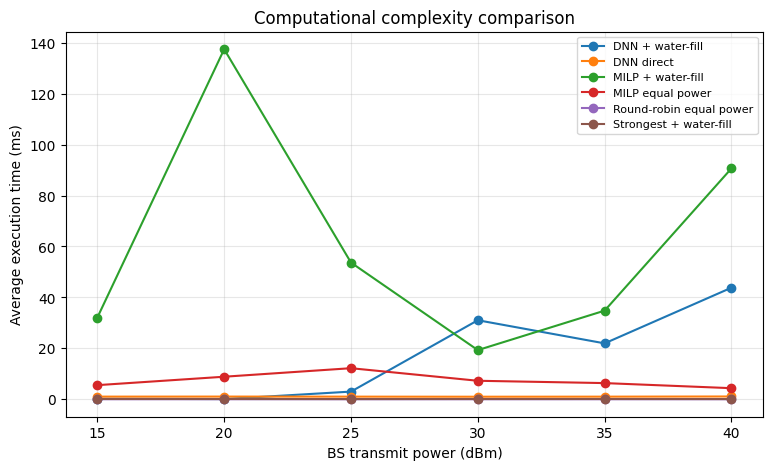

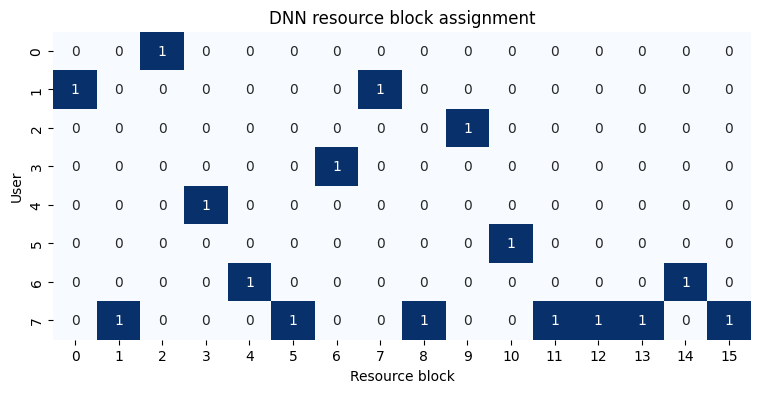

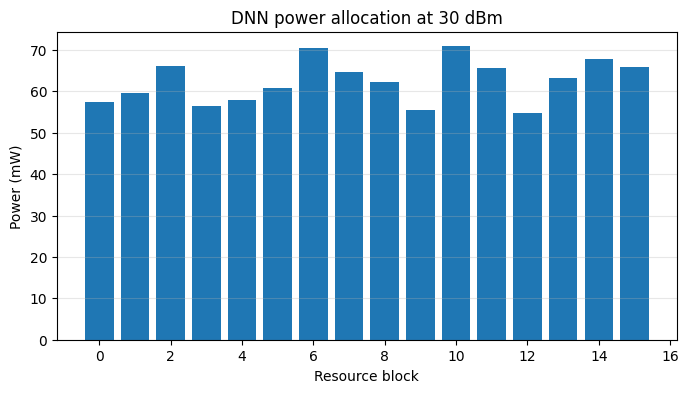

Task 3 results saved successfully.


In [17]:

# Cell 14 — Task 3 Monte Carlo with execution-time measurement

def simulate_task3(n_channels=20):

    records = []

    start_total = time.perf_counter()

    channel_samples = [
        generate_channel()[0]
        for _ in range(n_channels)
    ]

    total = n_channels * len(P_MAX_DBM_VALUES)
    completed = 0

    for channel_id, g in enumerate(channel_samples):

        for p_dbm in P_MAX_DBM_VALUES:

            pmax = dbm_to_watt(float(p_dbm))

            methods = {}
            execution_times = {}
            solver_status = {}

            # ------------------------------------------------
            # 1. Round Robin + Equal Power
            # ------------------------------------------------
            t0 = time.perf_counter()

            x_rr = round_robin_assignment()

            p_rr = np.full(N, pmax/N)

            methods["Round-robin equal power"] = (
                x_rr, p_rr
            )

            execution_times["Round-robin equal power"] = (
                time.perf_counter()-t0
            )*1000

            solver_status["Round-robin equal power"] = True

            # ------------------------------------------------
            # 2. Strongest User + Water Filling
            # ------------------------------------------------
            t0 = time.perf_counter()

            x_strong = strongest_assignment(g)

            p_strong, ok_strong = constrained_waterfill(
                g, x_strong, pmax
            )

            if not ok_strong:
                p_strong = np.full(N, pmax/N)

            methods["Strongest + water-fill"] = (
                x_strong, p_strong
            )

            execution_times["Strongest + water-fill"] = (
                time.perf_counter()-t0
            )*1000

            solver_status["Strongest + water-fill"] = ok_strong

            # ------------------------------------------------
            # 3. MILP + Equal Power
            # ------------------------------------------------
            t0 = time.perf_counter()

            x_milp, ok_milp, message = solve_milp_equal_power(
                g, pmax
            )

            p_milp_equal = np.full(N, pmax/N)

            methods["MILP equal power"] = (
                x_milp, p_milp_equal
            )

            execution_times["MILP equal power"] = (
                time.perf_counter()-t0
            )*1000

            solver_status["MILP equal power"] = ok_milp

            # ------------------------------------------------
            # 4. MILP + Water Filling
            # ------------------------------------------------
            t0 = time.perf_counter()

            p_milp_wf, ok_milp_wf = constrained_waterfill(
                g, x_milp, pmax
            )

            if not ok_milp_wf:
                p_milp_wf = p_milp_equal.copy()

            methods["MILP + water-fill"] = (
                x_milp, p_milp_wf
            )

            execution_times["MILP + water-fill"] = (
                time.perf_counter()-t0
            )*1000

            solver_status["MILP + water-fill"] = ok_milp_wf

            # ------------------------------------------------
            # 5. DNN Direct Allocation
            # ------------------------------------------------
            t0 = time.perf_counter()

            x_dnn, power_fraction = predict_dnn(
                resource_dnn, g, pmax
            )

            p_dnn = power_fraction * pmax

            methods["DNN direct"] = (
                x_dnn, p_dnn
            )

            execution_times["DNN direct"] = (
                time.perf_counter()-t0
            )*1000

            solver_status["DNN direct"] = True

            # ------------------------------------------------
            # 6. DNN + Water Filling
            # ------------------------------------------------
            t0 = time.perf_counter()

            p_hybrid, ok_hybrid = constrained_waterfill(
                g, x_dnn, pmax
            )

            if not ok_hybrid:
                p_hybrid = p_dnn.copy()

            methods["DNN + water-fill"] = (
                x_dnn, p_hybrid
            )

            execution_times["DNN + water-fill"] = (
                time.perf_counter()-t0
            )*1000

            solver_status["DNN + water-fill"] = ok_hybrid

            # ------------------------------------------------
            # Evaluate all methods on the same channel.
            # ------------------------------------------------
            for name, (assignment, power) in methods.items():

                metrics = evaluate_allocation(
                    g, assignment, power
                )

                records.append({

                    "Pmax_dBm": float(p_dbm),

                    "Channel_ID": channel_id,

                    "Method": name,

                    "Sum_rate_Mbps": metrics["Sum_rate_Mbps"],

                    "QoS_users_pct": metrics["QoS_users_pct"],

                    "Jain_fairness": metrics["Jain_fairness"],

                    "Rate_5th_percentile_Mbps":
                        metrics["Rate_5th_percentile_Mbps"],

                    "Total_power_W": np.sum(power),

                    "Execution_time_ms":
                        execution_times[name],

                    "Power_constraint_satisfied":
                        np.sum(power) <= pmax + 1e-9,

                    "QoS_solver_feasible":
                        solver_status[name]
                })

            completed += 1

            if completed % 5 == 0 or completed == total:

                print(
                    f"Progress: {completed}/{total} | "
                    f"Elapsed: "
                    f"{time.perf_counter()-start_total:.1f} seconds"
                )

    results = pd.DataFrame(records)

    print(
        "\nSimulation completed in "
        f"{time.perf_counter()-start_total:.2f} seconds."
    )

    return results


# Run Monte Carlo simulation.
task3_results = simulate_task3(
    n_channels=20
)


# Average results over channel realizations.
summary = (
    task3_results
    .groupby(["Pmax_dBm", "Method"])
    .mean(numeric_only=True)
    .reset_index()
)

display(summary.round(3))


# ------------------------------------------------
# Performance comparison plots.
# ------------------------------------------------

fig, axs = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

plot_specs = [

    (
        "Sum_rate_Mbps",
        "Sum rate (Mbps)",
        "Sum rate vs BS power"
    ),

    (
        "QoS_users_pct",
        "Users meeting QoS (%)",
        "QoS satisfaction vs BS power"
    ),

    (
        "Jain_fairness",
        "Jain fairness index",
        "Jain fairness vs BS power"
    ),

    (
        "Rate_5th_percentile_Mbps",
        "5th-percentile rate (Mbps)",
        "5th-percentile user rate"
    )
]

for ax, (column, ylabel, title) in zip(
    axs.flat, plot_specs
):

    for method, data in task3_results.groupby("Method"):

        avg = data.groupby("Pmax_dBm")[column].mean()

        ax.plot(
            avg.index,
            avg.values,
            marker="o",
            label=method
        )

    ax.set_title(title)
    ax.set_xlabel("BS transmit power (dBm)")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

axs[0, 0].legend(fontsize=7)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# Computational time comparison.
# ------------------------------------------------

plt.figure(figsize=(9, 5))

for method, data in task3_results.groupby("Method"):

    avg_time = data.groupby("Pmax_dBm")[
        "Execution_time_ms"
    ].mean()

    plt.plot(
        avg_time.index,
        avg_time.values,
        marker="o",
        label=method
    )

plt.xlabel("BS transmit power (dBm)")
plt.ylabel("Average execution time (ms)")
plt.title("Computational complexity comparison")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)
plt.show()


# ------------------------------------------------
# Representative DNN assignment and power.
# ------------------------------------------------

g_visual, _, _ = generate_channel()

x_visual, p_fraction_visual = predict_dnn(
    resource_dnn,
    g_visual,
    dbm_to_watt(30)
)

p_visual = (
    p_fraction_visual * dbm_to_watt(30)
)

plt.figure(figsize=(9, 4))

sns.heatmap(
    x_visual,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)

plt.xlabel("Resource block")
plt.ylabel("User")
plt.title("DNN resource block assignment")
plt.show()


plt.figure(figsize=(8, 4))

plt.bar(
    np.arange(N),
    p_visual*1000
)

plt.xlabel("Resource block")
plt.ylabel("Power (mW)")
plt.title("DNN power allocation at 30 dBm")
plt.grid(axis="y", alpha=0.3)
plt.show()


# Save all results.
task3_results.to_csv(
    "/content/task3_allocation_results.csv",
    index=False
)

summary.to_csv(
    "/content/task3_summary.csv",
    index=False
)

print("Task 3 results saved successfully.")


Existing Task 1 results found.


,MCS,SNR_dB,BLER,Source_BER,Frame_errors,Frames_tested
0,QPSK 1/2,0.0,0.991667,0.138078,119,120
1,QPSK 1/2,3.0,0.025000,0.000259,3,120
2,QPSK 1/2,6.0,0.000000,0.000000,0,120
3,QPSK 1/2,9.0,0.000000,0.000000,0,120
4,QPSK 1/2,12.0,0.000000,0.000000,0,120


,SNR_dB,Selected_MCS,Estimated_BLER,Spectral_efficiency
0,0,Outage,1.000000,0.0
1,1,Outage,1.000000,0.0
2,2,QPSK 1/2,0.093839,1.0
3,3,QPSK 1/2,0.028926,1.0
4,4,QPSK 1/2,0.015121,1.0
5,5,QPSK 1/2,0.007905,1.0
6,6,QPSK 1/2,0.004132,1.0
7,7,QPSK 3/4,0.045883,1.5
8,8,16-QAM 1/2,0.069584,2.0
9,9,16-QAM 1/2,0.020661,2.0


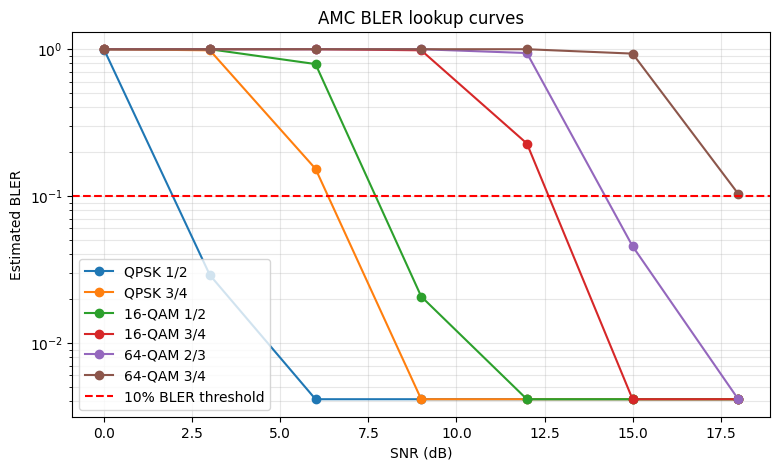

Average estimated Huffman bits per sentence: 510.236
Calculating AMC goodput at 15 dBm
Calculating AMC goodput at 20 dBm
Calculating AMC goodput at 25 dBm
Calculating AMC goodput at 30 dBm
Calculating AMC goodput at 35 dBm
Calculating AMC goodput at 40 dBm


,Pmax_dBm,Method,Estimated_correct_sentences_per_second
0,15,DNN + water-fill,5527.345644
1,15,DNN direct,5527.345644
2,15,MILP + water-fill,20042.555884
3,15,MILP equal power,20074.686276
4,15,Round-robin equal power,8171.806031
5,15,Strongest + water-fill,20304.312267
6,20,DNN + water-fill,8319.193556
7,20,DNN direct,8319.193556
8,20,MILP + water-fill,17714.168646
9,20,MILP equal power,17732.504316


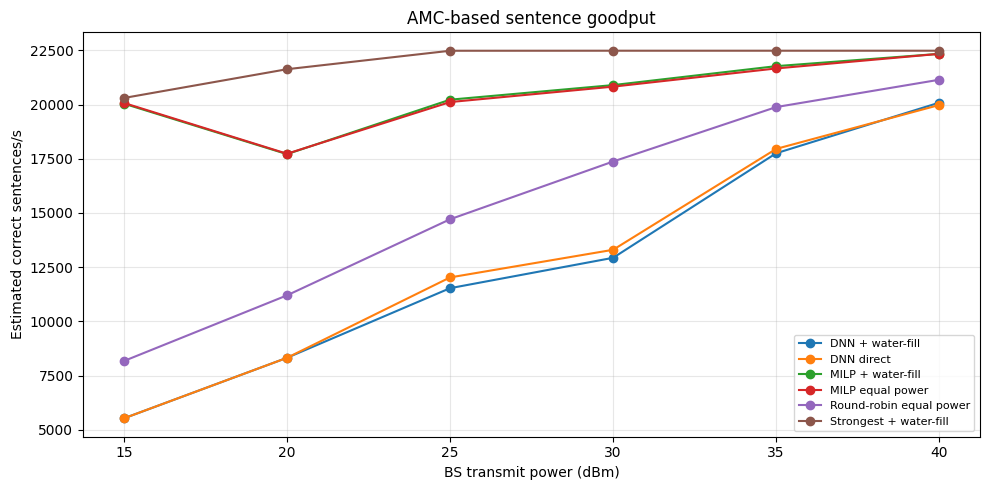

AMC and sentence goodput calculations completed.


In [18]:

# Cell 15 — AMC lookup, interpolation and sentence goodput (corrected)


# FIX: Ensure Task 1 results are available before AMC

if (
    "task1_results" not in globals()
    or not isinstance(task1_results, pd.DataFrame)
    or task1_results.empty
):

    print("Task 1 results not found. Running Task 1 simulation...")

    if "run_task1" not in globals():
        raise RuntimeError(
            "run_task1() is not defined. "
            "Execute Cell 7 first."
        )

    task1_results = run_task1(
        n_frames=N_FRAMES,
        snrs=SNR_DB,
        fading=False
    )

    print("Task 1 results generated successfully.")

else:
    print("Existing Task 1 results found.")

display(task1_results.head())

from sklearn.isotonic import IsotonicRegression
import ast

MCS_EFFICIENCY = {
    "QPSK 1/2": 1.0,
    "QPSK 3/4": 1.5,
    "16-QAM 1/2": 2.0,
    "16-QAM 3/4": 3.0,
    "64-QAM 2/3": 4.0,
    "64-QAM 3/4": 4.5
}

# ------------------------------------------------
# 1. Build BLER lookup curves
# ------------------------------------------------

bler_curves = {}

for mcs_name in MCS_EFFICIENCY:

    data = task1_results[
        task1_results["MCS"] == mcs_name
    ].sort_values("SNR_dB")

    if data.empty:
        raise ValueError(f"No Task 1 results found for {mcs_name}")

    snr_values = data["SNR_dB"].to_numpy(dtype=float)
    errors = data["Frame_errors"].to_numpy(dtype=float)
    frames = data["Frames_tested"].to_numpy(dtype=float)

    # Jeffreys-smoothed BLER
    bler_values = (errors + 0.5) / (frames + 1.0)

    isotonic = IsotonicRegression(
        increasing=False,
        out_of_bounds="clip"
    )

    fitted_bler = isotonic.fit_transform(
        snr_values,
        bler_values
    )

    bler_curves[mcs_name] = {
        "SNR": snr_values,
        "BLER": np.clip(fitted_bler, 1e-8, 1.0)
    }


# ------------------------------------------------
# 2. Estimate BLER using interpolation
# ------------------------------------------------

def estimate_bler(mcs_name, snr_db):

    curve = bler_curves[mcs_name]

    snr_values = curve["SNR"]
    bler_values = curve["BLER"]

    # Conservative handling outside measured range
    if snr_db < snr_values.min():
        return 1.0

    if snr_db > snr_values.max():
        return float(bler_values[-1])

    estimated_log_bler = np.interp(
        snr_db,
        snr_values,
        np.log10(bler_values)
    )

    return float(10**estimated_log_bler)


# ------------------------------------------------
# 3. Adaptive Modulation and Coding selection
# ------------------------------------------------

def select_amc(snr_db, bler_limit=0.10):

    candidates = []

    for mcs_name, efficiency in MCS_EFFICIENCY.items():

        predicted_bler = estimate_bler(
            mcs_name,
            snr_db
        )

        if predicted_bler <= bler_limit:

            candidates.append({
                "MCS": mcs_name,
                "Efficiency": efficiency,
                "BLER": predicted_bler
            })

    if not candidates:
        return None, 1.0

    best = max(
        candidates,
        key=lambda x: x["Efficiency"]
    )

    return best["MCS"], best["BLER"]


# ------------------------------------------------
# 4. Generate AMC lookup table
# ------------------------------------------------

AMC_SNR_VALUES = np.arange(0, 20, 1)

amc_records = []

for snr in AMC_SNR_VALUES:

    mcs, bler = select_amc(snr)

    amc_records.append({
        "SNR_dB": snr,
        "Selected_MCS": mcs if mcs else "Outage",
        "Estimated_BLER": bler,
        "Spectral_efficiency": (
            MCS_EFFICIENCY[mcs] if mcs else 0.0
        )
    })

amc_lookup = pd.DataFrame(amc_records)

display(amc_lookup)


# ------------------------------------------------
# 5. Plot BLER lookup curves
# ------------------------------------------------

plt.figure(figsize=(9, 5))

for name in MCS_EFFICIENCY:

    curve = bler_curves[name]

    plt.semilogy(
        curve["SNR"],
        curve["BLER"],
        marker="o",
        label=name
    )

plt.axhline(
    0.10,
    linestyle="--",
    color="red",
    label="10% BLER threshold"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Estimated BLER")
plt.title("AMC BLER lookup curves")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


# ------------------------------------------------
# 6. SAFE SENTENCE PREPROCESSING
# ------------------------------------------------

def normalize_sentence(sentence):

    # Handle list/tuple dataset entries
    if isinstance(sentence, (list, tuple)):
        sentence = " ".join(map(str, sentence))

    sentence = str(sentence).strip()

    # Handle strings containing list representations
    if sentence.startswith("[") and sentence.endswith("]"):
        try:
            parsed = ast.literal_eval(sentence)

            if isinstance(parsed, (list, tuple)):
                sentence = " ".join(map(str, parsed))
        except (ValueError, SyntaxError):
            pass

    return sentence


def safe_huffman_bit_length(sentence):

    sentence = normalize_sentence(sentence)

    # Count only characters supported by the existing Huffman tree.
    known_lengths = [
        len(HUFF_CODES[ch])
        for ch in sentence
        if ch in HUFF_CODES
    ]

    # Estimate unsupported-character length using the
    # average length of known Huffman codes.
    if not known_lengths:
        return 1

    average_length = np.mean([
        len(code) for code in HUFF_CODES.values()
    ])

    known_count = len(known_lengths)

    unknown_count = sum(
        ch not in HUFF_CODES for ch in sentence
    )

    estimated_bits = (
        sum(known_lengths)
        + unknown_count * average_length
    )

    return max(1, int(np.ceil(estimated_bits)))


# Calculate average source bits safely.
valid_sentences = [
    normalize_sentence(s)
    for s in test_sentences[:min(500, len(test_sentences))]
]

sentence_lengths = [
    safe_huffman_bit_length(s)
    for s in valid_sentences
    if s
]

if not sentence_lengths:
    raise ValueError("No valid test sentences available.")

mean_sentence_bits = float(np.mean(sentence_lengths))

print("Average estimated Huffman bits per sentence:",
      mean_sentence_bits)


# ------------------------------------------------
# 7. Estimate per-RB successful payload throughput
# ------------------------------------------------

def estimate_per_rb_goodput(
    g,
    assignment,
    power,
    mean_sentence_bits
):

    successful_bps = 0.0
    selected_mcs = []

    for n in range(N):

        users = np.where(assignment[:, n] > 0)[0]

        if len(users) == 0:
            continue

        u = int(users[0])

        snr_linear = (
            g[u, n] * power[n] / NOISE_W
        )

        snr_db = 10 * np.log10(
            max(snr_linear, 1e-15)
        )

        mcs, bler = select_amc(snr_db)

        if mcs is None:

            selected_mcs.append("Outage")
            continue

        spectral_efficiency = MCS_EFFICIENCY[mcs]

        rb_goodput = (
            RB_BW
            * spectral_efficiency
            * (1.0 - bler)
        )

        successful_bps += rb_goodput

        selected_mcs.append(mcs)

    sentence_rate = (
        successful_bps / max(mean_sentence_bits, 1.0)
    )

    return sentence_rate, successful_bps, selected_mcs


# ------------------------------------------------
# 8. Monte Carlo sentence goodput comparison
# ------------------------------------------------

GOODPUT_CHANNELS = 10

goodput_records = []

for p_dbm in P_MAX_DBM_VALUES:

    pmax = dbm_to_watt(float(p_dbm))

    print(f"Calculating AMC goodput at {p_dbm} dBm")

    for channel_id in range(GOODPUT_CHANNELS):

        g, _, _ = generate_channel()

        # Conventional allocation methods
        method_allocations = benchmark_methods(g, pmax)

        # DNN direct allocation
        x_dnn, p_fraction = predict_dnn(
            resource_dnn,
            g,
            pmax
        )

        p_dnn = p_fraction * pmax

        method_allocations["DNN direct"] = (
            x_dnn,
            p_dnn
        )

        # DNN + constrained water filling
        p_hybrid, ok_hybrid = constrained_waterfill(
            g,
            x_dnn,
            pmax
        )

        if not ok_hybrid:
            p_hybrid = p_dnn.copy()

        method_allocations["DNN + water-fill"] = (
            x_dnn,
            p_hybrid
        )

        # Evaluate all methods
        for method, (x, p) in method_allocations.items():

            cps, bps, selected = estimate_per_rb_goodput(
                g,
                x,
                p,
                mean_sentence_bits
            )

            goodput_records.append({
                "Pmax_dBm": p_dbm,
                "Channel_ID": channel_id,
                "Method": method,
                "Estimated_correct_sentences_per_second": cps,
                "Successful_payload_rate_bps": bps,
                "Selected_MCS_per_assigned_RB": ", ".join(selected)
            })


# ------------------------------------------------
# 9. Generate results table
# ------------------------------------------------

goodput_df = pd.DataFrame(goodput_records)

goodput_summary = (
    goodput_df
    .groupby(["Pmax_dBm", "Method"])
    ["Estimated_correct_sentences_per_second"]
    .mean()
    .reset_index()
)

display(goodput_summary)


# ------------------------------------------------
# 10. Plot sentence goodput
# ------------------------------------------------

plt.figure(figsize=(10, 5))

for method, data in goodput_summary.groupby("Method"):

    plt.plot(
        data["Pmax_dBm"],
        data["Estimated_correct_sentences_per_second"],
        marker="o",
        label=method
    )

plt.xlabel("BS transmit power (dBm)")
plt.ylabel("Estimated correct sentences/s")
plt.title("AMC-based sentence goodput")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# 11. Save output tables
# ------------------------------------------------

amc_lookup.to_csv(
    "/content/AMC_lookup.csv",
    index=False
)

goodput_df.to_csv(
    "/content/sentence_goodput.csv",
    index=False
)

goodput_summary.to_csv(
    "/content/sentence_goodput_summary.csv",
    index=False
)

print("AMC and sentence goodput calculations completed.")


In [19]:
# Cell 16 — Master execution note and ZIP archive
def run_all_experiments():
    # The notebook executes experiments sequentially above to make intermediate
    # validation and debugging visible. This function summarizes their outputs.
    return {
        "task1_rows": len(task1_results),
        "task2_awgn_rows": len(ae_awgn),
        "task2_rayleigh_rows": len(ae_rayleigh),
        "task3_rows": len(task3_results),
        "dataset": corpus_name
    }

print(run_all_experiments())

# Export CSV results and plots generated in the notebook output folder
with zipfile.ZipFile('/content/project_outputs.zip','w',zipfile.ZIP_DEFLATED) as zf:
    for root,dirs,files in os.walk('/content/project_outputs'):
        for fn in files:
            path=os.path.join(root,fn)
            zf.write(path,arcname=os.path.relpath(path,'/content'))
print("Created /content/project_outputs.zip")

{'task1_rows': 42, 'task2_awgn_rows': 7, 'task2_rayleigh_rows': 7, 'task3_rows': 720, 'dataset': 'NLTK Brown corpus'}
Created /content/project_outputs.zip
